In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, optimizers

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 26, 26, 5)      │            50 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 13, 13, 5)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 11, 11, 10)     │           460 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 5, 5, 10)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flat (Flatten)                  │ (None, 250)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop (Dropout)                  │ (None, 250)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense1 (Dense)                  │ (None, 128)            │        32,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense2 (Dense)                  │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,928 (132.53 KB)

 Trainable params: 33,928 (132.53 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
938/938 - 13s - 14ms/step - accuracy: 0.8685 - loss: 0.4193 - val_accuracy: 0.9682 - val_loss: 0.1089
Epoch 2/10
938/938 - 9s - 10ms/step - accuracy: 0.9400 - loss: 0.1922 - val_accuracy: 0.9749 - val_loss: 0.0806
Epoch 3/10
938/938 - 6s - 7ms/step - accuracy: 0.9532 - loss: 0.1479 - val_accuracy: 0.9814 - val_loss: 0.0577
Epoch 4/10
938/938 - 6s - 7ms/step - accuracy: 0.9604 - loss: 0.1269 - val_accuracy: 0.9838 - val_loss: 0.0488
Epoch 5/10
938/938 - 9s - 9ms/step - accuracy: 0.9639 - loss: 0.1119 - val_accuracy: 0.9854 - val_loss: 0.0430
Epoch 6/10
938/938 - 9s - 9ms/step - accuracy: 0.9681 - loss: 0.1003 - val_accuracy: 0.9854 - val_loss: 0.0436
Epoch 7/10
938/938 - 8s - 9ms/step - accuracy: 0.9693 - loss: 0.0970 - val_accuracy: 0.9873 - val_loss: 0.0391
Epoch 8/10
938/938 - 9s - 9ms/step - accuracy: 0.9716 - loss: 0.0894 - val_accuracy: 0.9884 - val_loss: 0.0341
Epoch 9/10
938/938 - 9s - 10ms/step - accuracy: 0.9732 - loss: 0.0840 - val_accuracy: 0.9889 - val_loss: 0.03

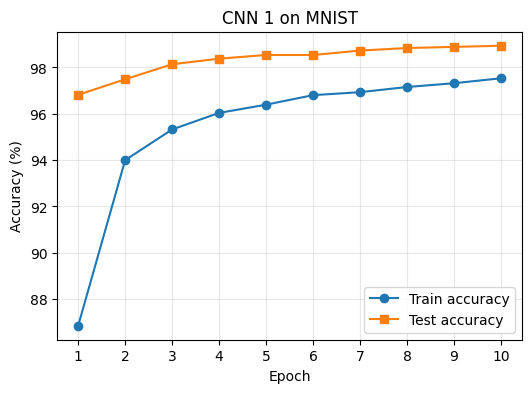

In [ ]:
keras.utils.set_random_seed(0)

(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

x_train = x_train.astype("float32").reshape(-1, 28, 28, 1) / 255.0
x_test  = x_test.astype("float32").reshape(-1, 28, 28, 1) / 255.0
y_train = keras.utils.to_categorical(y_train, 10)
y_test  = keras.utils.to_categorical(y_test, 10)

#Model

inputs = layers.Input (shape=(28,28,1,))
x1 = layers.Conv2D (5, kernel_size = (3,3), activation = 'relu', name = 'conv1')(inputs)
x2 = layers.MaxPooling2D (pool_size = (2,2),name = 'pool1')(x1)
x3 = layers.Conv2D (10, (3,3), activation = 'relu', name = 'conv2')(x2)
x4 = layers.MaxPooling2D (pool_size = (2,2), name = 'pool2')(x3)
x5 = layers.Flatten(name='flat')(x4)
x6 = layers.Dropout(0.45,name='drop')(x5)
x7 = layers.Dense (128, activation = 'relu', name = 'dense1')(x6)
outputs = layers.Dense (10, activation = 'softmax', name= 'dense2')(x7)
CNN1 = models.Model (inputs = inputs, outputs = outputs)
CNN1.summary()

adam = optimizers.Adam(learning_rate=0.001)
CNN1.compile (loss = keras.losses.categorical_crossentropy, optimizer = adam, metrics = ['accuracy'])
hist = CNN1.fit(x_train, y_train, batch_size=64, epochs=10, validation_data=(x_test, y_test), verbose=2)

# hist.history['accuracy'] is measured during the epoch with dropout on,
# so it can be slightly lower than test accuracy. evaluate() runs with dropout off.

train_loss, train_acc = CNN1.evaluate(x_train, y_train, verbose=0)
test_loss, test_acc   = CNN1.evaluate(x_test,  y_test,  verbose=0)
print(f"Final train accuracy: {train_acc*100:.2f} %")
print(f"Final test  accuracy: {test_acc*100:.2f} %")

CNN1.save("cnn1.keras")
np.savez("history.npz", **{k: np.array(v) for k, v in hist.history.items()})

ep = np.arange(1, 11)
plt.figure(figsize=(6, 4))
plt.plot(ep, np.array(hist.history["accuracy"]) * 100, "o-", label="Train accuracy")
plt.plot(ep, np.array(hist.history["val_accuracy"]) * 100, "s-", label="Test accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("CNN 1 on MNIST")
plt.xticks(ep)
plt.grid(alpha=0.3)
plt.legend()
plt.savefig("accuracy_plot.png", dpi=150)
print("Saved cnn1.keras, history.npz, accuracy_plot.png")

In [3]:
cal = models.Model(inputs, [x1, x3, x7])
acts = cal.predict(x_train[:5000], verbose=0)

weights, biases, D = [], [], []

s = 1 / 255

for i, name in enumerate(['conv1', 'conv2', 'dense1', 'dense2']):
    w, b = CNN1.get_layer(name).get_weights()

    sw = float(np.abs(w).max()) / 127 or 1.0
    weights.append(np.rint(w / sw).astype(np.int64).flatten() + 128)

    s = s * sw
    biases.append(np.rint(b / s).astype(np.int64))

    if i < 3:
        d = max(1, int(np.ceil(float(acts[i].max()) / (255 * s))))
        D.append(d)
        s = s * d

print('Divisors:', D)

Divisors: [521, 166, 385]


In [4]:
labels = np.argmax(y_test, axis=1)

idx = np.concatenate([
    np.where(labels == i)[0][:10] for i in range(10)
])

images = np.rint(x_test[idx] * 255).astype(np.int64)

def save_mem(name, data, bits):
    data = np.asarray(data, dtype=np.int64).flatten()
    np.savetxt(name + '.mem', data & (2**bits - 1),
               fmt=f'%0{bits//4}x')

save_mem('weights', np.concatenate(weights), 8)
save_mem('biases', np.concatenate(biases), 32)
save_mem('divisors', D, 32)
save_mem('images', images, 8)
save_mem('labels', labels[idx], 8)

In [7]:
import pandas as pd
results = pd.read_csv("simulation_results.csv")

py_pred = np.argmax(CNN1.predict(x_test[idx], verbose=0), axis=1)
v_pred = results["predicted"].to_numpy()

print("Python accuracy:", np.mean(py_pred == labels[idx])*100)
print("Prediction agreement:", np.sum(py_pred == v_pred), "/ 100")

Python accuracy: 100.0
Prediction agreement: 100 / 100
